## Homework 4

In [2]:
import pandas as pd
import numpy as np
from sklearn.metrics import auc
import matplotlib.pyplot as plt

### Data preparation

In [3]:
df = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv")
df.head(1).T

,0
lead_source,organic_search
industry,technology
employment_status,employed
location,europe
annual_income,88160.0
number_of_courses_viewed,3
interaction_count,4
lead_score,0.64
converted,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [5]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [6]:
categorical = df.columns[df.dtypes == "str"].tolist()
numeric = df.columns[(df.dtypes == "float") | (df.dtypes == "int")].tolist()
numeric.remove("converted")
y = df.converted
X = df[numeric + categorical]

In [7]:
for c in df.columns:
    if c in categorical:
        df[c] = df[c].fillna("NA")
    elif c in numeric:
        df[c] = df[c].fillna(0.0)

In [8]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [9]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [10]:
df_full_train.shape[0], df_train.shape[0], df_val.shape[0], df_test.shape[0]

(4000, 3000, 1000, 1000)

### Question 1

In [11]:
from sklearn.metrics import roc_auc_score

for column in numeric:
    auc = roc_auc_score(df_train['converted'], df_train[column])

    if auc > 0.5:
        print(f"{column}: {auc:.3f}")
    else:
        auc = roc_auc_score(df_train['converted'], -df_train[column])
        print(f"{column}: {auc:.3f}")

annual_income: 0.608
number_of_courses_viewed: 0.723
interaction_count: 0.765
lead_score: 0.788


### Question 2

In [12]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train[categorical + numeric].to_dict(orient='records'))

In [13]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, df_train["converted"])

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [14]:
X_val = dv.transform(df_val[categorical + numeric].to_dict(orient='records'))
y_val = df_val["converted"]
y_pred = model.predict_proba(X_val)[:, 1]

from sklearn.metrics import roc_auc_score
auc = roc_auc_score(y_val, y_pred)
round(auc,3)

0.732

### Question 3

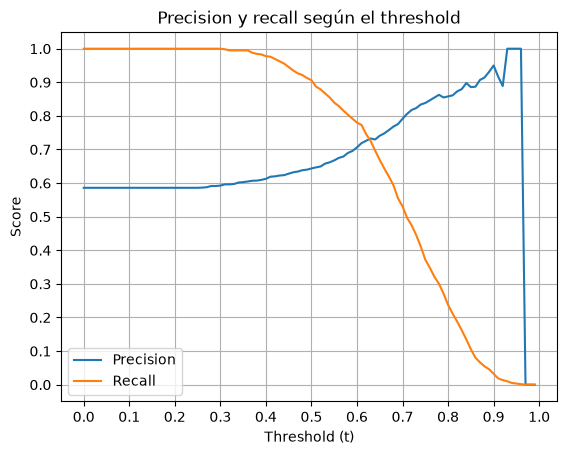

In [15]:
from sklearn.metrics import precision_score, recall_score

thresholds = np.arange(0.0, 1.0, 0.01)

precision_values = []
recall_values = []

for threshold in thresholds:
    y_pred_binary = y_pred >= threshold
    precision_values.append(precision_score(y_val, y_pred_binary, zero_division=0))
    recall_values.append(recall_score(y_val, y_pred_binary, zero_division=0))

plt.plot(thresholds, precision_values, label="Precision")
plt.plot(thresholds, recall_values, label="Recall")
plt.xlabel("Threshold (t)")
plt.ylabel("Score")
plt.title("Precision y recall según el threshold")
plt.legend()
plt.grid(True)
plt.yticks(np.arange(0, 1.1, 0.1))
plt.xticks(np.arange(0, 1.1, 0.1))
plt.show()




### Question 4

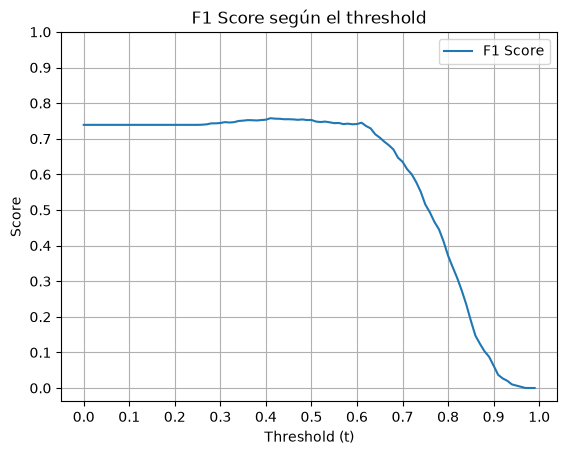

In [16]:
from sklearn.metrics import f1_score

thresholds = np.arange(0.0, 1.0, 0.01)

f1_values = []

for threshold in thresholds:
    y_pred_binary = y_pred >= threshold
    f1_values.append(f1_score(y_val, y_pred_binary, zero_division=0))

plt.plot(thresholds, f1_values, label="F1 Score")
plt.xlabel("Threshold (t)")
plt.ylabel("Score")
plt.title("F1 Score según el threshold")
plt.legend()
plt.grid(True)
plt.yticks(np.arange(0, 1.1, 0.1))
plt.xticks(np.arange(0, 1.1, 0.1))
plt.show()

### Question 5

In [18]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for fold, (train_idx, val_idx) in enumerate(kfold.split(df_full_train), start=1):
    df_fold_train = df_full_train.iloc[train_idx]
    df_fold_val = df_full_train.iloc[val_idx]

    dv_fold = DictVectorizer(sparse=False)
    X_fold_train = dv_fold.fit_transform(
        df_fold_train[categorical + numeric].to_dict(orient="records")
    )
    X_fold_val = dv_fold.transform(
        df_fold_val[categorical + numeric].to_dict(orient="records")
    )

    fold_model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
    fold_model.fit(X_fold_train, df_fold_train["converted"])

    y_fold_pred = fold_model.predict_proba(X_fold_val)[:, 1]
    score = roc_auc_score(df_fold_val["converted"], y_fold_pred)
    scores.append(score)
    print(f"Fold {fold}: AUC = {score:.3f}")

print(f"Mean AUC: {np.mean(scores):.3f}")
print(f"Std AUC: {np.std(scores):.3f}")

Fold 1: AUC = 0.731
Fold 2: AUC = 0.730
Fold 3: AUC = 0.736
Fold 4: AUC = 0.741
Fold 5: AUC = 0.721
Mean AUC: 0.732
Std AUC: 0.007


### Question 6

In [20]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for C in [0.000001, 0.001, 1]:
    for fold, (train_idx, val_idx) in enumerate(kfold.split(df_full_train), start=1):
        df_fold_train = df_full_train.iloc[train_idx]
        df_fold_val = df_full_train.iloc[val_idx]

        dv_fold = DictVectorizer(sparse=False)
        X_fold_train = dv_fold.fit_transform(
            df_fold_train[categorical + numeric].to_dict(orient="records")
        )
        X_fold_val = dv_fold.transform(
            df_fold_val[categorical + numeric].to_dict(orient="records")
        )

        fold_model = LogisticRegression(solver="liblinear", C=C, max_iter=1000)
        fold_model.fit(X_fold_train, df_fold_train["converted"])

        y_fold_pred = fold_model.predict_proba(X_fold_val)[:, 1]
        score = roc_auc_score(df_fold_val["converted"], y_fold_pred)
        scores.append(score)
        print(f"C={C}, Fold {fold}: AUC = {score:.3f}")

    print(f"C={C}: Mean AUC: {np.mean(scores):.3f}")
    print(f"C={C}: Std AUC: {np.std(scores):.3f}\n")

C=1e-06, Fold 1: AUC = 0.594
C=1e-06, Fold 2: AUC = 0.640
C=1e-06, Fold 3: AUC = 0.600
C=1e-06, Fold 4: AUC = 0.636
C=1e-06, Fold 5: AUC = 0.613
C=1e-06: Mean AUC: 0.617
C=1e-06: Std AUC: 0.019

C=0.001, Fold 1: AUC = 0.750
C=0.001, Fold 2: AUC = 0.748
C=0.001, Fold 3: AUC = 0.758
C=0.001, Fold 4: AUC = 0.758
C=0.001, Fold 5: AUC = 0.731
C=0.001: Mean AUC: 0.683
C=0.001: Std AUC: 0.068

C=1, Fold 1: AUC = 0.731
C=1, Fold 2: AUC = 0.730
C=1, Fold 3: AUC = 0.736
C=1, Fold 4: AUC = 0.741
C=1, Fold 5: AUC = 0.721
C=1: Mean AUC: 0.699
C=1: Std AUC: 0.060

